<a href="https://colab.research.google.com/github/udjonah/Paper-2-New/blob/main/Paper_2_New.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving Loan_Processing_Time_SME_Dataset.xlsx to Loan_Processing_Time_SME_Dataset.xlsx


In [2]:
import pandas as pd

Firms in file: 94,937
Estimation sample (SMEs, outcome defined, >= 5 peers): 15,009
Discouragement rate in estimation sample: 0.198

Objective 1, deciles of expected processing time:
               days   rate     lo     hi       n
days_decile                                     
0             8.233  0.205  0.185  0.225  1502.0
1            11.325  0.192  0.172  0.211  1519.0
2            13.613  0.132  0.115  0.149  1510.0
3            16.243  0.175  0.156  0.194  1475.0
4            19.204  0.199  0.179  0.220  1500.0
5            21.906  0.173  0.154  0.192  1501.0
6            24.923  0.228  0.206  0.249  1503.0
7            27.897  0.193  0.173  0.213  1501.0
8            33.193  0.222  0.201  0.243  1515.0
9            46.353  0.265  0.243  0.287  1483.0

Objective 1 regression sample: 14,768
  No controls          b =  0.0241  se = 0.0086  p = 0.005
  Controls + survey FE b =  0.0019  se = 0.0060  p = 0.751

Objective 1, survey-level scatter: 104 surveys, weighted slope = 0.0046

/tmp/ipykernel_521/723631060.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return smf.ols(formula, data=data).fit(
/tmp/ipykernel_521/723631060.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return smf.ols(formula, data=data).fit(
/tmp/ipykernel_521/723631060.py:54: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return smf.ols(formula, data=data).fit(



Objective 3, effect of 1 SD longer expected processing time by group:
           group            level       b     se      p     n
       Firm size            Small  0.0092 0.0119 0.4401  8182
       Firm size           Medium  0.0056 0.0062 0.3721  6586
        Firm age  Older (>10 yrs)  0.0027 0.0064 0.6724 10410
        Firm age Young (<=10 yrs) -0.0046 0.0122 0.7089  4358
Liquidity buffer     No overdraft  0.0054 0.0115 0.6358  4651
Liquidity buffer    Has overdraft -0.0077 0.0088 0.3820  4428

Figures saved to ./figures/


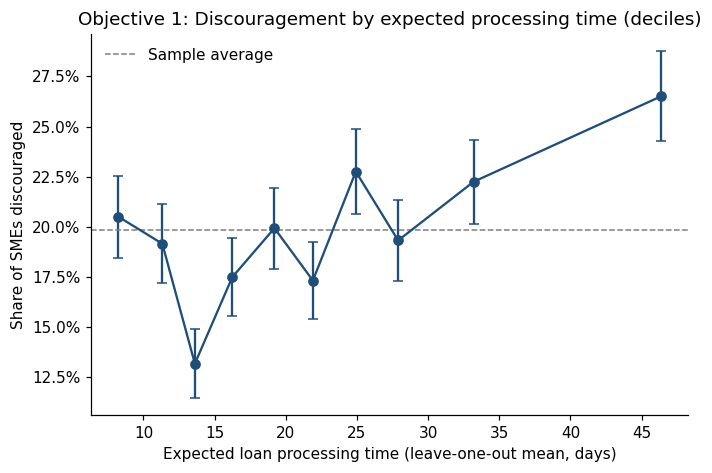

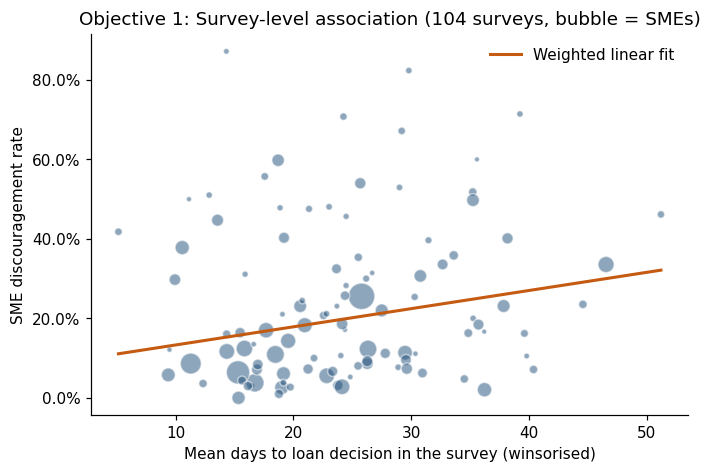

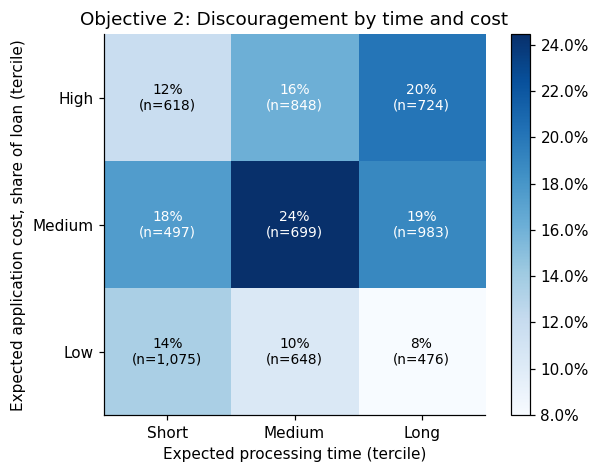

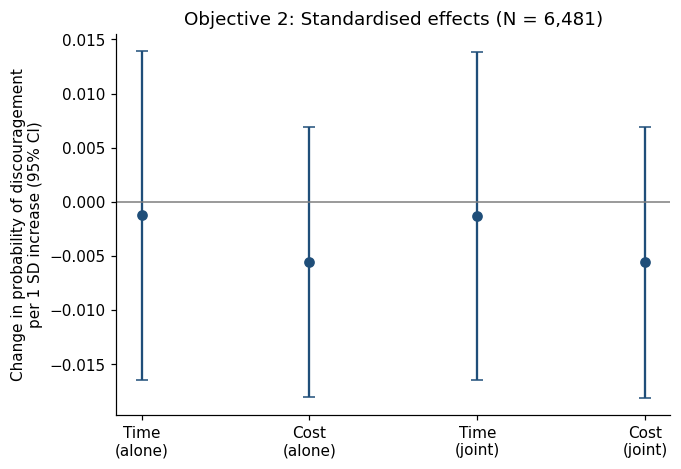

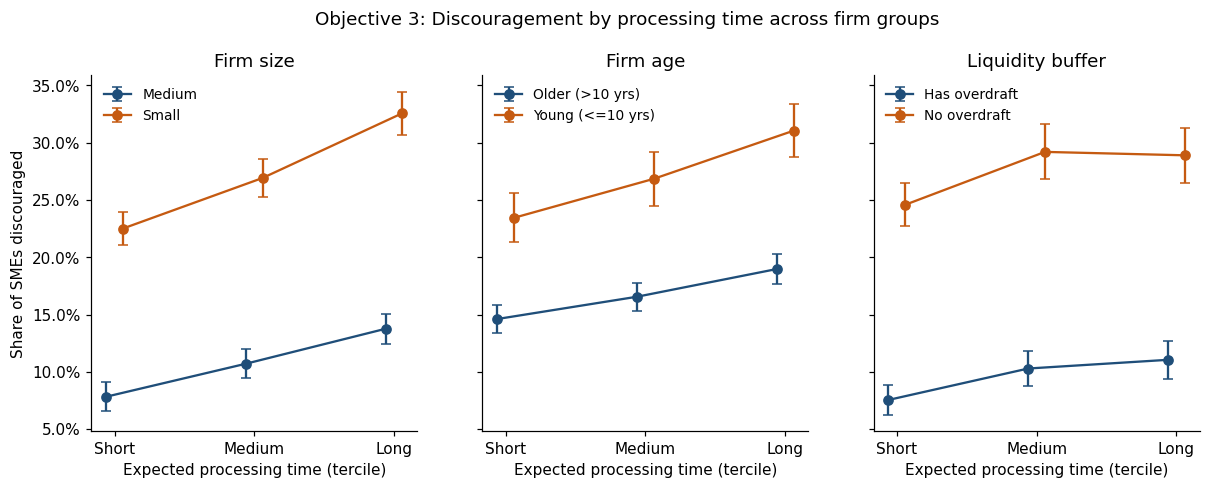

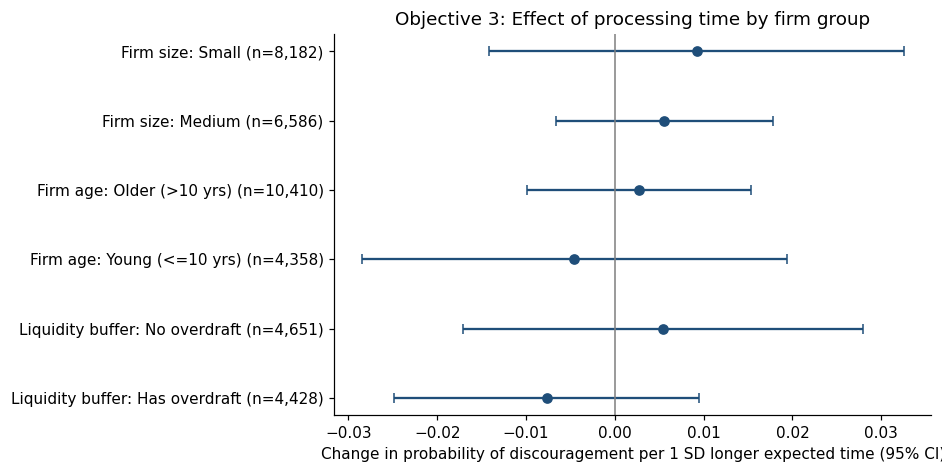

In [3]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ------------------------------------------------------------------
# Settings
# ------------------------------------------------------------------
DATA_FILE = "Loan_Processing_Time_SME_Dataset.xlsx"
OUT_DIR = "figures"
MIN_PEERS = 5          # minimum other applicants behind each leave-one-out mean
MIN_FIRMS_COUNTRY = 30 # minimum SMEs per survey for the country-level scatter
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})
BLUE, ORANGE, GREY = "#1F4E79", "#C55A11", "#7F7F7F"

# ------------------------------------------------------------------
# Load data and define the estimation sample
# ------------------------------------------------------------------
df = pd.read_excel(DATA_FILE, sheet_name="Data")

# SMEs that needed finance and either applied (0) or were discouraged by
# complex procedures / expected rejection (1), with a reliable LOO mean
est = df[(df["sme"] == 1)
         & df["discouraged_main"].notna()
         & (df["loo_days_cszs_n"] >= MIN_PEERS)].copy()

est["log_age"] = np.log1p(est["firm_age"])
est["log_emp"] = np.log1p(est["employees"])
est["z_days"] = (est["loo_days_cszs"] - est["loo_days_cszs"].mean()) / est["loo_days_cszs"].std()
est["cluster"] = est["cell_id"].astype("category").cat.codes

print(f"Firms in file: {len(df):,}")
print(f"Estimation sample (SMEs, outcome defined, >= {MIN_PEERS} peers): {len(est):,}")
print(f"Discouragement rate in estimation sample: {est['discouraged_main'].mean():.3f}")


def rate_ci(series):
    """Share and 95% normal-approximation confidence interval."""
    n = series.notna().sum()
    p = series.mean()
    se = np.sqrt(p * (1 - p) / n) if n > 0 else np.nan
    return pd.Series({"rate": p, "lo": p - 1.96 * se, "hi": p + 1.96 * se, "n": n})


def fit_lpm(data, formula):
    """Linear probability model with cell-clustered standard errors."""
    return smf.ols(formula, data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["cluster"]})


CONTROLS = ("log_age + log_emp + foreign_owned + exporter + female_top_manager"
            " + audited_statements + loo_approval_cszs + C(survey) + C(sector)")

# ==================================================================
# OBJECTIVE 1
# Examine the extent to which longer expected loan processing time
# increases the likelihood that SMEs become discouraged borrowers.
# ==================================================================

# Figure 1a: binned scatter of discouragement on expected processing time
est["days_decile"] = pd.qcut(est["loo_days_cszs"], 10, labels=False, duplicates="drop")
bins = est.groupby("days_decile")[["loo_days_cszs", "discouraged_main"]].apply(
    lambda g: pd.concat([pd.Series({"days": g["loo_days_cszs"].mean()}),
                         rate_ci(g["discouraged_main"])]))
print("\nObjective 1, deciles of expected processing time:")
print(bins.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(bins["days"], bins["rate"],
            yerr=[bins["rate"] - bins["lo"], bins["hi"] - bins["rate"]],
            fmt="o-", color=BLUE, capsize=3)
ax.axhline(est["discouraged_main"].mean(), color=GREY, ls="--", lw=1,
           label="Sample average")
ax.set_xlabel("Expected loan processing time (leave-one-out mean, days)")
ax.set_ylabel("Share of SMEs discouraged")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
ax.set_title("Objective 1: Discouragement by expected processing time (deciles)")
ax.legend(frameon=False)
fig.savefig(f"{OUT_DIR}/obj1a_binned_discouragement.png")

# Within-survey estimate: same comparison after survey and sector fixed effects
cols1 = ["discouraged_main", "z_days", "log_age", "log_emp", "foreign_owned", "exporter",
         "female_top_manager", "audited_statements", "loo_approval_cszs",
         "survey", "sector", "cluster"]
s1 = est[cols1].dropna()
m1_raw = fit_lpm(s1, "discouraged_main ~ z_days")
m1_fe = fit_lpm(s1, f"discouraged_main ~ z_days + {CONTROLS}")
print(f"\nObjective 1 regression sample: {int(m1_fe.nobs):,}")
print(f"  No controls          b = {m1_raw.params['z_days']: .4f}  se = {m1_raw.bse['z_days']:.4f}  p = {m1_raw.pvalues['z_days']:.3f}")
print(f"  Controls + survey FE b = {m1_fe.params['z_days']: .4f}  se = {m1_fe.bse['z_days']:.4f}  p = {m1_fe.pvalues['z_days']:.3f}")

# Figure 1b: country (survey) level association
ctry_rate = est.groupby("survey").agg(disc=("discouraged_main", "mean"),
                                      n=("discouraged_main", "size"))
ctry_days = df.groupby("survey")["decision_days_w"].mean().rename("days")
ctry = ctry_rate.join(ctry_days).query("n >= @MIN_FIRMS_COUNTRY").dropna()
w = ctry["n"]
b1, b0 = np.polyfit(ctry["days"], ctry["disc"], 1, w=np.sqrt(w))
print(f"\nObjective 1, survey-level scatter: {len(ctry)} surveys, weighted slope = {b1:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(ctry["days"], ctry["disc"], s=w / w.max() * 300, alpha=0.5,
           color=BLUE, edgecolor="white")
xs = np.linspace(ctry["days"].min(), ctry["days"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color=ORANGE, lw=2, label="Weighted linear fit")
ax.set_xlabel("Mean days to loan decision in the survey (winsorised)")
ax.set_ylabel("SME discouragement rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
ax.set_title(f"Objective 1: Survey-level association ({len(ctry)} surveys, bubble = SMEs)")
ax.legend(frameon=False)
fig.savefig(f"{OUT_DIR}/obj1b_country_scatter.png")

# ==================================================================
# OBJECTIVE 2
# Determine whether loan processing time deters SME credit demand
# independently of the monetary cost of applying, and compare the two.
# ==================================================================
sub = est[est["loo_cost_cszs"].notna() & (est["loo_cost_cszs_n"] >= MIN_PEERS)].copy()
sub["z_days"] = (sub["loo_days_cszs"] - sub["loo_days_cszs"].mean()) / sub["loo_days_cszs"].std()
sub["z_cost"] = (sub["loo_cost_cszs"] - sub["loo_cost_cszs"].mean()) / sub["loo_cost_cszs"].std()
print(f"\nObjective 2 subsample (time and cost both observed): {len(sub):,} SMEs "
      f"in {sub['survey'].nunique()} surveys")

# Figure 2a: discouragement by terciles of time x terciles of cost
sub["time_t"] = pd.qcut(sub["loo_days_cszs"], 3, labels=["Short", "Medium", "Long"])
sub["cost_t"] = pd.qcut(sub["loo_cost_cszs"], 3, labels=["Low", "Medium", "High"])
grid = sub.pivot_table(index="cost_t", columns="time_t", values="discouraged_main",
                       aggfunc="mean", observed=False)
cnt = sub.pivot_table(index="cost_t", columns="time_t", values="discouraged_main",
                      aggfunc="size", observed=False)
print("\nObjective 2, discouragement rate by cost (rows) x time (columns):")
print(grid.round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(grid.values, cmap="Blues", origin="lower")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"{grid.values[i, j]:.0%}\n(n={cnt.values[i, j]:,})",
                ha="center", va="center", fontsize=9,
                color="white" if grid.values[i, j] > np.nanmean(grid.values) else "black")
ax.set_xticks(range(3), grid.columns)
ax.set_yticks(range(3), grid.index)
ax.set_xlabel("Expected processing time (tercile)")
ax.set_ylabel("Expected application cost, share of loan (tercile)")
ax.set_title("Objective 2: Discouragement by time and cost")
fig.colorbar(im, ax=ax, format=plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
fig.savefig(f"{OUT_DIR}/obj2a_time_cost_heatmap.png")

# Figure 2b: standardised effects of time and cost in one model
cols2 = ["discouraged_main", "z_days", "z_cost", "log_age", "log_emp", "foreign_owned",
         "exporter", "female_top_manager", "audited_statements", "loo_approval_cszs",
         "survey", "sector", "cluster"]
s2 = sub[cols2].dropna()
m_time = fit_lpm(s2, f"discouraged_main ~ z_days + {CONTROLS}")
m_cost = fit_lpm(s2, f"discouraged_main ~ z_cost + {CONTROLS}")
m_both = fit_lpm(s2, f"discouraged_main ~ z_days + z_cost + {CONTROLS}")
wald = m_both.t_test("z_days - z_cost = 0")
print(f"\nObjective 2 regression sample: {int(m_both.nobs):,}")
for name, m, v in [("Time only", m_time, "z_days"), ("Cost only", m_cost, "z_cost"),
                   ("Both: time", m_both, "z_days"), ("Both: cost", m_both, "z_cost")]:
    print(f"  {name:<11} b = {m.params[v]: .4f}  se = {m.bse[v]:.4f}  p = {m.pvalues[v]:.3f}")
print(f"  Test time = cost: p = {float(wald.pvalue):.3f}")

labels = ["Time\n(alone)", "Cost\n(alone)", "Time\n(joint)", "Cost\n(joint)"]
coefs = [m_time.params["z_days"], m_cost.params["z_cost"],
         m_both.params["z_days"], m_both.params["z_cost"]]
ses = [m_time.bse["z_days"], m_cost.bse["z_cost"],
       m_both.bse["z_days"], m_both.bse["z_cost"]]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.errorbar(range(4), coefs, yerr=1.96 * np.array(ses), fmt="o", capsize=4,
            color=BLUE, ecolor=BLUE)
ax.axhline(0, color=GREY, lw=1)
ax.set_xticks(range(4), labels)
ax.set_ylabel("Change in probability of discouragement\nper 1 SD increase (95% CI)")
ax.set_title(f"Objective 2: Standardised effects (N = {int(m_both.nobs):,})")
fig.savefig(f"{OUT_DIR}/obj2b_coefficients.png")

# ==================================================================
# OBJECTIVE 3
# Assess how the effect of processing time varies with firm size, age and
# liquidity position, and whether it is strongest for liquidity-constrained SMEs.
# Liquidity proxy: whether the firm has an overdraft facility (k7), i.e. a
# short-term buffer that reduces the cost of waiting for a decision.
# ==================================================================
est["time_t"] = pd.qcut(est["loo_days_cszs"], 3, labels=["Short", "Medium", "Long"])
est["size_grp"] = est["size_class"].str.split(" ").str[0]
est["age_grp"] = pd.cut(est["firm_age"], [-1, 10, np.inf],
                        labels=["Young (<=10 yrs)", "Older (>10 yrs)"]).astype(object)
est["liq_grp"] = est["overdraft"].map({1: "Has overdraft", 0: "No overdraft"})

groups = [("size_grp", "Firm size"), ("age_grp", "Firm age"),
          ("liq_grp", "Liquidity buffer")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (g, title) in zip(axes, groups):
    tab = est.dropna(subset=[g]).groupby([g, "time_t"], observed=True)["discouraged_main"] \
             .apply(rate_ci).unstack()
    for k, (lvl, col) in enumerate(zip(tab.index.get_level_values(0).unique(), [BLUE, ORANGE])):
        t = tab.loc[lvl]
        x = np.arange(len(t)) + (k - 0.5) * 0.12
        ax.errorbar(x, t["rate"], yerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]],
                    fmt="o-", color=col, capsize=3, label=lvl)
    ax.set_xticks(range(3), ["Short", "Medium", "Long"])
    ax.set_xlabel("Expected processing time (tercile)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Share of SMEs discouraged")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
fig.suptitle("Objective 3: Discouragement by processing time across firm groups", y=1.02)
fig.savefig(f"{OUT_DIR}/obj3a_heterogeneity_rates.png")

# Figure 3b: effect of 1 SD longer processing time, estimated within each group
rows = []
for g, title in groups:
    for lvl in est[g].dropna().unique():
        cols3 = ["discouraged_main", "z_days", "log_age", "log_emp", "foreign_owned",
                 "exporter", "female_top_manager", "audited_statements",
                 "loo_approval_cszs", "survey", "sector", "cluster"]
        d3 = est.loc[est[g] == lvl, cols3].dropna()
        m = fit_lpm(d3, f"discouraged_main ~ z_days + {CONTROLS}")
        rows.append({"group": title, "level": lvl, "b": m.params["z_days"],
                     "se": m.bse["z_days"], "p": m.pvalues["z_days"], "n": int(m.nobs)})
het = pd.DataFrame(rows)
print("\nObjective 3, effect of 1 SD longer expected processing time by group:")
print(het.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
y = np.arange(len(het))[::-1]
ax.errorbar(het["b"], y, xerr=1.96 * het["se"], fmt="o", color=BLUE, capsize=3)
ax.axvline(0, color=GREY, lw=1)
ax.set_yticks(y, [f"{r.group}: {r.level} (n={r.n:,})" for r in het.itertuples()])
ax.set_xlabel("Change in probability of discouragement per 1 SD longer expected time (95% CI)")
ax.set_title("Objective 3: Effect of processing time by firm group")
fig.savefig(f"{OUT_DIR}/obj3b_group_effects.png")

print(f"\nFigures saved to ./{OUT_DIR}/")